In [ ]:
!pip install nucleus-cdk==0.5.0rc2 | tail -n2

Analyze time-series data from platereader experiments.

## Setup 

In [1]:
%load_ext autoreload
%autoreload 2
    
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from cdk import logging
log = logging.setup_logging(logging.ERROR)

# Import the cdk platereader module
from cdk.instruments import platereader as pr

## Load Data

In [2]:
# Specify file paths
data_file = "20260617-112324-cytation5-pure-timecourse-gfp.txt"
platemap_file = "20260617-3 DNA.csv"

# Load data
result = pr.load_platereader_data(
    data_file=data_file,
    platemap_file=platemap_file,
    platereader="biotek" # options: "biotek"
)

[06/18/26 12:07:05] INFO     Found 1 plate blocks                  biotek.py:105
                    INFO     Parsing plate block 1                 biotek.py:112
                    INFO     Read metadata section, found 2 read   biotek.py:213
                             block(s).                                          
                    INFO     Parsed 2 segment(s) successfully.     biotek.py:466
                    INFO     Found 0 segment(s) that could not be  biotek.py:467
                             associated with existing read data.                


The output is a list of `PlateReaderResult` objects; if you did more than one read on the plate reader, the results will be in separate objects.

In [3]:
print(result)

PlateReaderResult with the following 2 blocks:
0: (657, 37) kinetic read with reads: GFP-G70:485,528 (Fluorescence) (Plate 'Plate 1')
1: (657, 37) kinetic read with reads: GFP-Gext:485,528 (Fluorescence) (Plate 'Plate 1')


Here there were two reads with different gains but the same excitation/emission spectrum, on one plate. If we want just the `GFP-Gext` read, this corresponds to block index 1, so we can extract that block by indexing:

In [4]:
desired_index = 1
data = result[desired_index]
data

(657, 37) kinetic read with reads: GFP-Gext:485,528 (Fluorescence)

## Plot Raw Curves

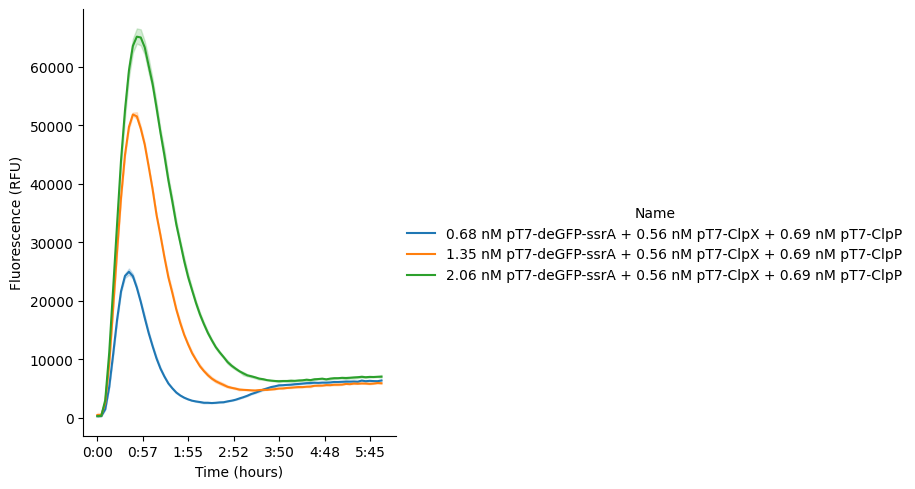

In [6]:
#| label: 20260617-3dna-neb
a=data.plot()
a.savefig('Raw Plot.png',dpi=300)